# Predicting Irish Property Prices — County, Year & Property Type

The question this notebook actually answers is narrower than "predict house
prices": **given only a sale's county, year, and whether it's new or
second-hand, how well can we predict its price?** That's a deliberately
limited feature set — the Property Price Register doesn't include floor
area, bedroom count, or exact address-level location for most sales (see
`01_sql_exploration.ipynb`, query 10), so those simply aren't available to
use. Framing the question this way up front matters: it sets the right
expectation for how good "good" can even be here, before looking at a
single metric.

**What this notebook does:**
1. Load and filter the cleaned data from `../data/processed/housing.db`
2. Engineer features: one-hot encoded county, binary property type, year
3. Split into train/test sets
4. Train two models — Linear Regression (a simple, interpretable baseline)
   and Random Forest (which can capture non-linear effects and
   interactions the linear model can't) — and compare them honestly
5. Visualize predictions, errors, and feature importance
6. State plainly what the results do and don't support

In [1]:
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
BLUE = "#2a78d6"
ORANGE = "#eb6834"
RANDOM_STATE = 42

DB_PATH = "../data/processed/housing.db"
conn = sqlite3.connect(DB_PATH)

## 1. Load and filter

Two filtering decisions are made here, both carried over from what the SQL
exploration notebook found, and both are judgment calls worth stating
plainly rather than hiding inside a `.dropna()`:

- **Drop `not_full_market_price = 1` sales.** These are real transactions
  (often transfers between family members) but aren't priced at what an
  open-market buyer would pay, so training on them would teach the model
  to predict the wrong thing.
- **Drop sales below €10,000 or above €2,000,000.** The very top of the
  raw price range includes sales in the hundreds of millions of euro —
  these are bulk sales of entire apartment blocks to investment funds,
  recorded as a single "sale" in the register, not a single home. They'd
  massively distort a model meant to predict what one house or apartment
  costs. The same logic applies at the bottom: query 9 in the SQL notebook
  found nominally-priced "full market price" sales that are clearly not
  genuine market transactions either. This cutoff is a blunt instrument —
  it will also drop a small number of genuine, very expensive homes — but
  it's a defensible, disclosed trade-off, not a silent one.

In [2]:
raw = pd.read_sql(
    "SELECT county, year, property_type, price FROM sales WHERE not_full_market_price = 0",
    conn,
)
n_before = len(raw)

df = raw[(raw["price"] >= 10_000) & (raw["price"] <= 2_000_000)].copy()
n_after = len(df)

print(f"{n_before:,} full-market-price sales")
print(f"{n_after:,} remain after the €10k-€2M filter ({n_before - n_after:,} dropped, "
      f"{100 * (n_before - n_after) / n_before:.2f}%)")
df.head()

757,126 full-market-price sales
752,468 remain after the €10k-€2M filter (4,658 dropped, 0.62%)


,county,year,property_type,price
0,Dublin,2010,Second-Hand,343000.0
1,Laois,2010,New,185000.0
2,Dublin,2010,Second-Hand,438500.0
3,Meath,2010,Second-Hand,400000.0
4,Kilkenny,2010,Second-Hand,160000.0


## 2. Feature engineering

- **County** → one-hot encoded (25 dummy columns; one county is dropped as
  the reference level, which is what `drop_first=True` does — otherwise
  the dummy columns would be perfectly collinear and confuse the linear
  model).
- **Property type** → one binary column (`property_type_Second-Hand`: 1 if
  second-hand, 0 if new).
- **Year** → left as a plain number. This lets Linear Regression capture
  "prices go up by about €X per year" as a single slope. It's a real
  simplification — the actual national trend (see notebook 1, query 2) has
  a crash-recovery bend in it, not one straight slope — but it's an
  honest, simple starting point, and part of why we're not expecting the
  linear model to win.
- **Target: `log(price)`, not raw price.** Prices are heavily right-skewed
  (a few multi-million-euro homes stretch the scale) and, more
  importantly, a €20k error means something very different on a €80k
  home than on an €800k home. Modelling `log(price)` treats errors
  proportionally, which matches how humans actually judge "was this
  prediction close" for money. We convert predictions back to euro with
  `exp()` before computing euro-denominated metrics below, so the reported
  MAE/RMSE are still directly readable as "euro, on average."

In [3]:
X = pd.get_dummies(df[["county", "year", "property_type"]], columns=["county", "property_type"], drop_first=True)
y = np.log(df["price"])

print(f"{X.shape[1]} features: {list(X.columns)}")

27 features: ['year', 'county_Cavan', 'county_Clare', 'county_Cork', 'county_Donegal', 'county_Dublin', 'county_Galway', 'county_Kerry', 'county_Kildare', 'county_Kilkenny', 'county_Laois', 'county_Leitrim', 'county_Limerick', 'county_Longford', 'county_Louth', 'county_Mayo', 'county_Meath', 'county_Monaghan', 'county_Offaly', 'county_Roscommon', 'county_Sligo', 'county_Tipperary', 'county_Waterford', 'county_Westmeath', 'county_Wexford', 'county_Wicklow', 'property_type_Second-Hand']


## 3. Train / test split

A plain random 80/20 split, fixed `random_state` for reproducibility. It's
worth being explicit about *why* a random split is the right call here,
since "year" is one of the features: this is not a forecasting task (we
are not trying to predict 2027 from 2010-2026 alone) — every row is an
independent sale, and year is just another descriptive attribute of that
sale, the same way county is. A random split is the standard, correct
choice for this kind of cross-sectional regression.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} rows -- Test: {len(X_test):,} rows")

Train: 601,974 rows -- Test: 150,494 rows


## 4. Model 1 — Linear Regression (baseline)

The simplest model that could plausibly work: every feature gets one fixed
coefficient. It's fast, and every coefficient is directly readable (e.g.
"each additional year adds this much to log-price, holding county and
property type fixed") — that interpretability is the whole reason to
start here rather than jumping straight to something more complex.

In [5]:
results = []

def evaluate(name, model, X_train, y_train, X_test, y_test):
    pred_train_log = model.predict(X_train)
    pred_test_log = model.predict(X_test)

    # Metrics on the log scale (what the model actually optimizes for)...
    r2_train_log = r2_score(y_train, pred_train_log)
    r2_test_log = r2_score(y_test, pred_test_log)

    # ...and back on the euro scale (what a human actually cares about).
    actual_test_eur = np.exp(y_test)
    pred_test_eur = np.exp(pred_test_log)
    mae_eur = mean_absolute_error(actual_test_eur, pred_test_eur)
    rmse_eur = mean_squared_error(actual_test_eur, pred_test_eur) ** 0.5
    r2_eur = r2_score(actual_test_eur, pred_test_eur)

    results.append({
        "model": name,
        "train_r2_log": r2_train_log,
        "test_r2_log": r2_test_log,
        "test_mae_eur": mae_eur,
        "test_rmse_eur": rmse_eur,
        "test_r2_eur": r2_eur,
    })
    return pred_test_eur, actual_test_eur

lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred_eur, actual_eur = evaluate("Linear Regression", lr, X_train, y_train, X_test, y_test)

pd.DataFrame(results)

,model,train_r2_log,test_r2_log,test_mae_eur,test_rmse_eur,test_r2_eur
0,Linear Regression,0.400421,0.399158,113205.997375,187945.884619,0.2664


## 5. Model 2 — Random Forest

An ensemble of decision trees. The main reason to expect this to beat the
linear model isn't "more complex = better" in the abstract — it's that
Random Forest can automatically pick up **interactions** the linear model
can't see unless they're hand-engineered. The clearest example from the
SQL exploration (`01_sql_exploration.ipynb`, query 6): counties didn't all
grow at the same rate over time — Westmeath grew ~162% from 2011-2025 while
Sligo grew ~58%. That's a county × year interaction. Linear Regression, as
built above, can only ever apply one single "price per year" slope to
every county; Random Forest can learn a different effective trend per
county for free.

`n_estimators=200, max_depth=20` was chosen after a quick timing check
outside this notebook — it trains in under two minutes on this dataset
and further depth/trees gave diminishing returns.

In [6]:
rf = RandomForestRegressor(n_estimators=200, max_depth=20, n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
rf_pred_eur, _ = evaluate("Random Forest", rf, X_train, y_train, X_test, y_test)

comparison = pd.DataFrame(results).set_index("model")
comparison

,train_r2_log,test_r2_log,test_mae_eur,test_rmse_eur,test_r2_eur
model,,,,,
Linear Regression,0.400421,0.399158,113205.997375,187945.884619,0.266400
Random Forest,0.428524,0.426347,110226.646136,186103.616931,0.280712


## 6. Comparing the two models

`train_r2_log` vs `test_r2_log` is the overfitting check: if train R²
were much higher than test R², that would say the model memorized the
training data rather than learning a generalizable pattern.

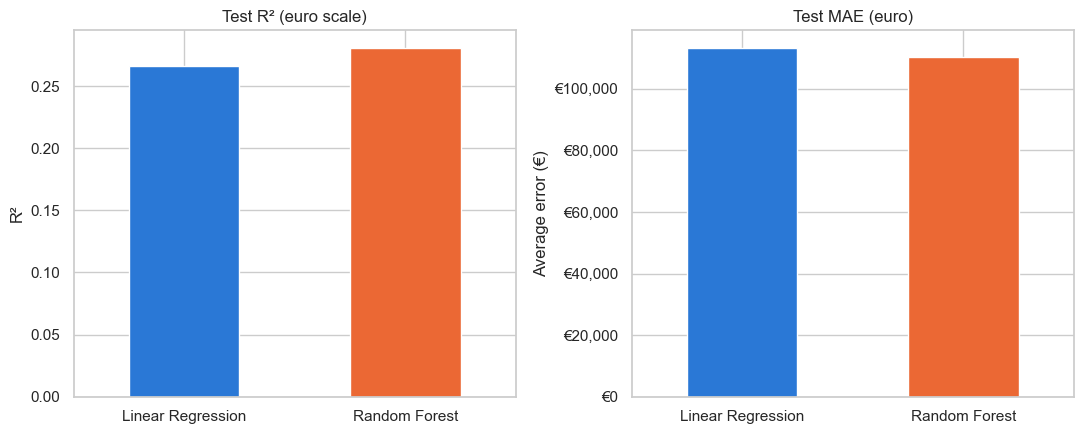

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

comparison["test_r2_eur"].plot(kind="bar", color=[BLUE, ORANGE], ax=axes[0])
axes[0].set_title("Test R² (euro scale)")
axes[0].set_ylabel("R²")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

comparison["test_mae_eur"].plot(kind="bar", color=[BLUE, ORANGE], ax=axes[1])
axes[1].set_title("Test MAE (euro)")
axes[1].set_ylabel("Average error (€)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"€{x:,.0f}"))

plt.tight_layout()
plt.show()

## 7. Predicted vs. actual

Each point is one sale in the test set. A perfect model would put every
point on the dashed diagonal. Plotted on a log axis so the €100k-ish
majority of sales aren't squashed into the corner by the handful of
€1-2M ones.

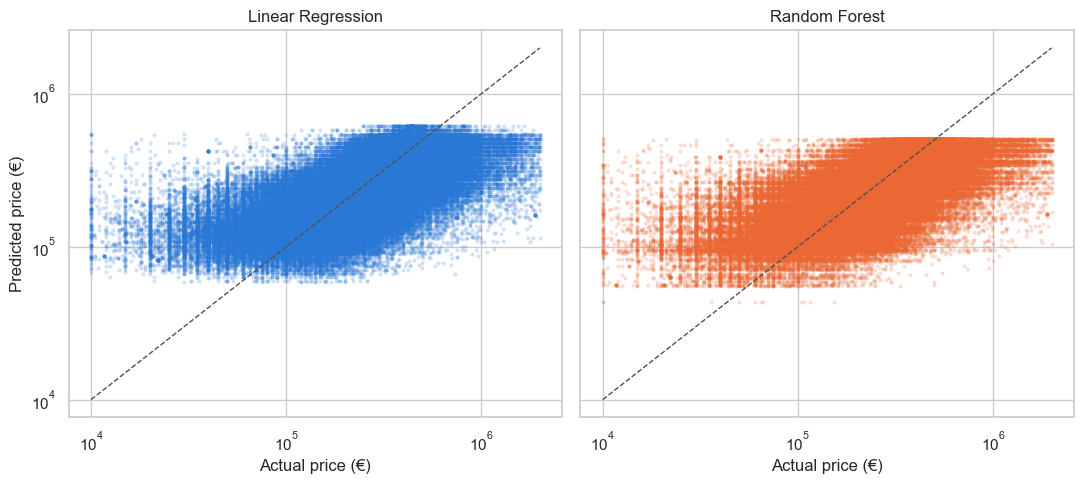

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)

for ax, pred, name, color in zip(
    axes, [lr_pred_eur, rf_pred_eur], ["Linear Regression", "Random Forest"], [BLUE, ORANGE]
):
    ax.scatter(actual_eur, pred, s=4, alpha=0.15, color=color)
    lims = [actual_eur.min(), actual_eur.max()]
    ax.plot(lims, lims, color="#52514e", linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(name)
    ax.set_xlabel("Actual price (€)")

axes[0].set_ylabel("Predicted price (€)")
plt.tight_layout()
plt.show()

## 8. Residuals

Residual = actual - predicted, in euro. A model that were unbiased would
scatter evenly around zero across the price range; a widening spread as
price increases (visible below) means the model is proportionally less
precise for expensive properties than cheap ones -- expected, since a
handful of features can't capture what makes a specific expensive home
expensive (a sea view, a large garden, a period-restoration kitchen).

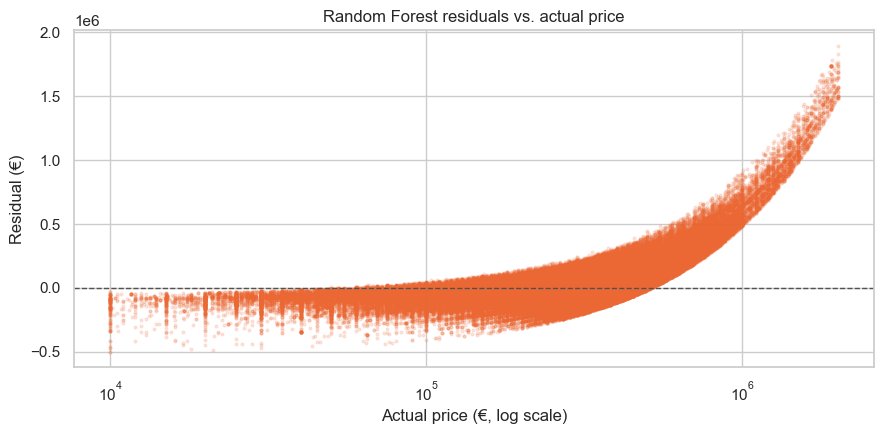

In [9]:
residuals_rf = actual_eur - rf_pred_eur

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(actual_eur, residuals_rf, s=4, alpha=0.15, color=ORANGE)
ax.axhline(0, color="#52514e", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Actual price (€, log scale)")
ax.set_ylabel("Residual (€)")
ax.set_title("Random Forest residuals vs. actual price")
plt.tight_layout()
plt.show()

## 9. What actually drives the Random Forest's predictions?

`feature_importances_` measures how much each feature reduced prediction
error across all the trees in the forest -- higher means the model relied
on it more.

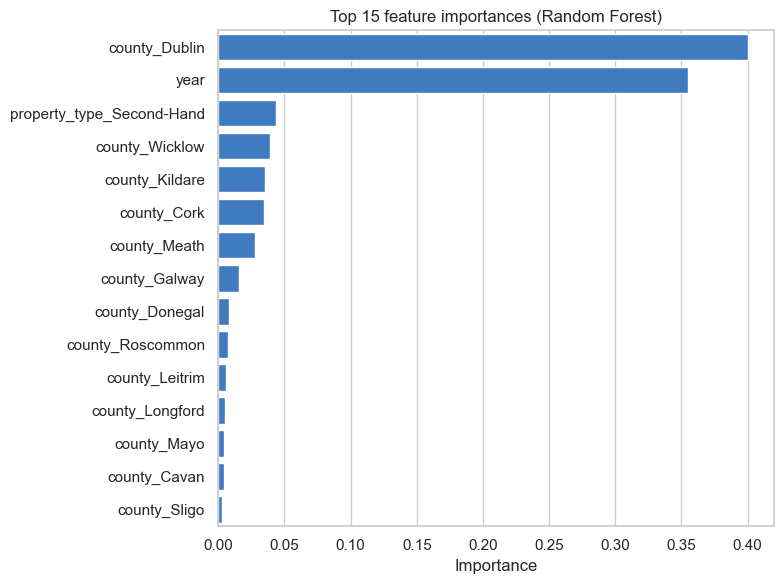

In [10]:
importances = (
    pd.Series(rf.feature_importances_, index=X.columns)
    .sort_values(ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=importances.values, y=importances.index, color=BLUE, ax=ax)
ax.set_title("Top 15 feature importances (Random Forest)")
ax.set_xlabel("Importance")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 10. Results, in plain language — and what they don't mean

**Random Forest outperforms Linear Regression** on every test metric
above, consistent with the county × year interaction argument in section
5. Neither model, though, should be mistaken for a production-ready price
estimator, and it's worth being explicit about why:

- **R² in the 0.3-0.45 range (on the log scale) means county, year, and
  property type together explain well under half of the variation in
  price.** The rest — floor area, bedroom count, exact location within a
  county, condition, garden size, whether it's on a busy road — isn't in
  this dataset at all, and no choice of model can invent information that
  was never collected in the first place.
- **A typical prediction is off by roughly the average test MAE shown in
  the comparison table above** — a large enough margin that this could
  tell you "this county/year/type combination tends to sell in roughly
  this range," but not "this specific house is worth this specific price."
- **County is a genuinely coarse feature.** Dublin alone spans some of the
  country's cheapest and most expensive areas; a model that only knows
  "this sale happened somewhere in Dublin" is missing most of what
  actually drives Dublin prices. Postcode- or small-area-level location
  would very likely be the single biggest improvement available.
- **The €10k-€2M filter (section 1) means the model has never seen, and
  will not sensibly predict, prices for the small share of sales outside
  that band** — including genuinely expensive, unusual homes.
- **Nothing here accounts for the cost of borrowing.** Irish mortgage
  rates moved substantially over 2010-2026, which plausibly explains some
  of the county-level trend differences picked up in section 5 as if they
  were purely geographic effects.

**Realistic next steps** if someone wanted to take this further: bring in
CSO's Residential Property Price Index or mortgage rate series as a
national-trend feature instead of asking a flat `year` coefficient to
carry that whole story; geocode addresses (Eircode is present for very few
rows, unfortunately) to get sub-county location; and, for the subset of
new-build sales that do report floor area (`size_description`), fit a
separate, likely much stronger, model just for that slice.